# Chapitre 9 - Cours 2 : arbres de régression et de classification (CART)

Ce notebook suit la section 9.2 du livre. Les arbres **partitionnent l'espace des
entrées en rectangles** et ajustent un modèle très simple (une constante) dans chacun.
Nous allons :

1. décrire les partitions binaires récursives (figure 9.2) ;
2. faire croître un arbre de **régression** (critère des moindres carrés, éq. (9.13)) ;
3. l'**élaguer** par le critère coût-complexité (éq. (9.16)) ;
4. passer à la **classification** : mesures d'impureté de Gini, d'entropie et d'erreur
   (figure 9.3) ;
5. discuter les autres questions pratiques (variables qualitatives, pertes, instabilité) ;
6. reproduire l'exemple **spam** : validation croisée (figure 9.4), arbre élagué
   (figure 9.5), table 9.3 et courbes ROC (figure 9.6).

Tout est implémenté à la main dans la classe `ArbreCART` du module `esl/ch09_arbres.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch09_arbres import (ArbreCART, cart_cv, impurity, trace_arbre, roc_curve,
                             auc, GAM, SPAM_NAMES)

set_style()
rng = np.random.RandomState(0)

## 1. Partitions binaires récursives (figure 9.2)

Considérons deux entrées $X_1, X_2\in[0,1]$. Une partition quelconque du carré par des
segments parallèles aux axes (panneau de gauche ci-dessous) produit des régions
difficiles à décrire. On se restreint donc aux partitions **binaires récursives** : on
coupe d'abord l'espace en deux selon une règle $X_j\le s$, puis on recoupe chacune des
deux moitiés, et ainsi de suite (panneau de droite).

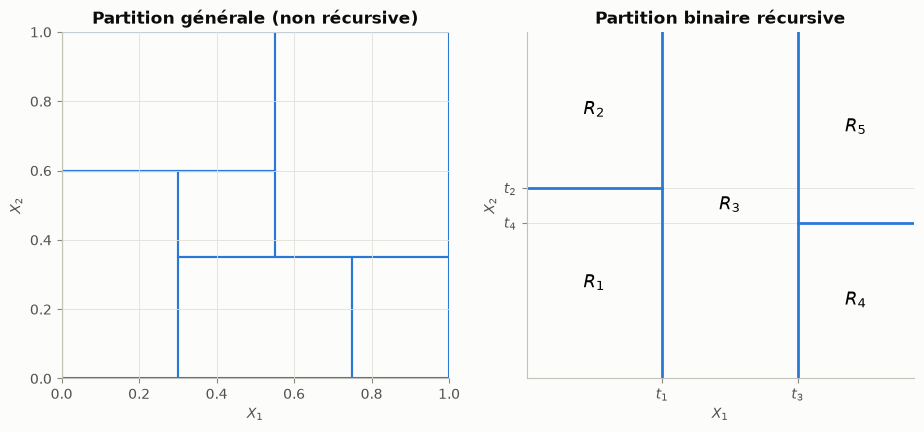

In [2]:
t1, t2, t3, t4 = 0.35, 0.55, 0.7, 0.45
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ax = axes[0]
for (x0, y0, w, h) in [(0, 0, .3, .6), (0, .6, .55, .4), (.3, 0, .45, .35), (.3, .35, .25, .25),
                       (.55, .35, .45, .65), (.75, 0, .25, .35)]:
    ax.add_patch(Rectangle((x0, y0), w, h, fill=False, lw=1.5, ec=BLUE))
ax.set(title="Partition générale (non récursive)", xlabel="$X_1$", ylabel="$X_2$",
       xlim=(0, 1), ylim=(0, 1))
ax = axes[1]
ax.plot([t1, t1], [0, 1], color=BLUE)
ax.plot([0, t1], [t2, t2], color=BLUE)
ax.plot([t3, t3], [0, 1], color=BLUE)
ax.plot([t3, 1], [t4, t4], color=BLUE)
for nom, (a, b) in {"$R_1$": (t1 / 2, t2 / 2), "$R_2$": (t1 / 2, (1 + t2) / 2),
                    "$R_3$": ((t1 + t3) / 2, .5), "$R_4$": ((1 + t3) / 2, t4 / 2),
                    "$R_5$": ((1 + t3) / 2, (1 + t4) / 2)}.items():
    ax.text(a, b, nom, ha="center", va="center", fontsize=13)
ax.set(title="Partition binaire récursive", xlabel="$X_1$", ylabel="$X_2$",
       xlim=(0, 1), ylim=(0, 1), xticks=[t1, t3], xticklabels=["$t_1$", "$t_3$"],
       yticks=[t4, t2], yticklabels=["$t_4$", "$t_2$"])
plt.show()

La partition de droite est obtenue ainsi : on coupe en $X_1=t_1$ ; la région
$X_1\le t_1$ est coupée en $X_2=t_2$ ; la région $X_1>t_1$ est coupée en $X_1=t_3$ ;
enfin la région $X_1>t_3$ est coupée en $X_2=t_4$. On obtient cinq régions
$R_1,\dots,R_5$ et le modèle (éq. (9.9))
$$\hat f(X) = \sum_{m=1}^5 c_m\,\mathbb 1\{(X_1,X_2)\in R_m\}.$$

Le même modèle se représente par un **arbre binaire** : on part de la racine (toutes les
données), une observation vérifiant la condition d'un nœud va à gauche, sinon à droite ;
les **feuilles** (nœuds terminaux) sont les régions $R_m$.

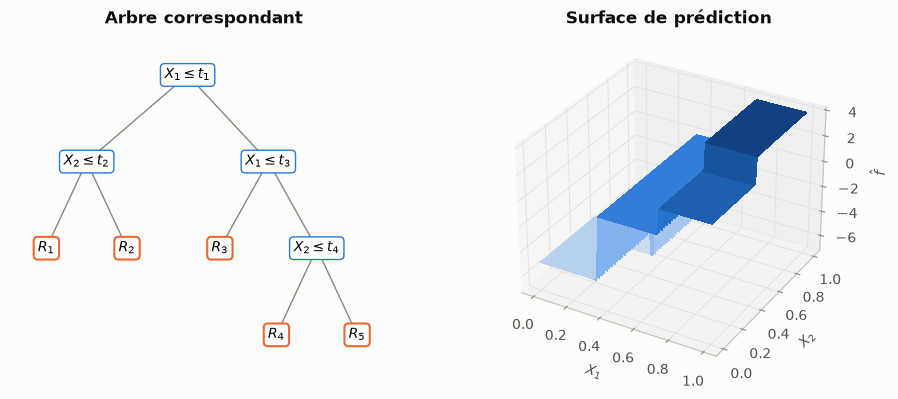

In [3]:
fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(1, 2, 1)
noeuds = {"r": (2, 3, r"$X_1\leq t_1$"), "a": (0.75, 2, r"$X_2\leq t_2$"),
          "b": (3, 2, r"$X_1\leq t_3$"), "c": (3.6, 1, r"$X_2\leq t_4$")}
feuilles = {"R1": (0.25, 1), "R2": (1.25, 1), "R3": (2.4, 1), "R4": (3.1, 0), "R5": (4.1, 0)}
aretes = [("r", "a"), ("r", "b"), ("a", "R1"), ("a", "R2"), ("b", "R3"), ("b", "c"),
          ("c", "R4"), ("c", "R5")]
pos = {k: v[:2] for k, v in noeuds.items()} | feuilles
for u, v in aretes:
    ax.plot(*zip(pos[u], pos[v]), color=GRAY, lw=1)
for k, (x0, y0, lab) in noeuds.items():
    ax.text(x0, y0, lab, ha="center", va="center",
            bbox=dict(boxstyle="round", fc="white", ec=BLUE))
for k, (x0, y0) in feuilles.items():
    ax.text(x0, y0, "$R_%s$" % k[1], ha="center", va="center",
            bbox=dict(boxstyle="round", fc="white", ec=ORANGE, lw=1.5))
ax.set(xlim=(-0.2, 4.6), ylim=(-0.5, 3.5), title="Arbre correspondant")
ax.axis("off")

ax3 = fig.add_subplot(1, 2, 2, projection="3d")
g = np.linspace(0, 1, 80)
G1, G2 = np.meshgrid(g, g)
c = {1: -5, 2: -7, 3: 0, 4: 2, 5: 4}
Z = np.where(G1 <= t1, np.where(G2 <= t2, c[1], c[2]),
             np.where(G1 <= t3, c[3], np.where(G2 <= t4, c[4], c[5])))
ax3.plot_surface(G1, G2, Z, cmap=SEQ, linewidth=0, antialiased=False)
ax3.set(xlabel="$X_1$", ylabel="$X_2$", zlabel=r"$\hat f$", title="Surface de prédiction")
plt.show()

Les valeurs $c_1=-5$, $c_2=-7$, $c_3=0$, $c_4=2$, $c_5=4$ sont celles choisies par le
livre. L'arbre est **très lisible** : avec plus de deux entrées, on ne peut plus dessiner
la partition, mais l'arbre se lit toujours de la même façon (« si… alors… »).

## 2. Arbres de régression

### La constante optimale dans une région

On dispose de $N$ observations $(x_i,y_i)$, $x_i\in\mathbb R^p$. Supposons la partition
$R_1,\dots,R_M$ fixée et le modèle $f(x)=\sum_m c_m\mathbb 1(x\in R_m)$ (éq. (9.10)). Le
critère des moindres carrés se découpe en une somme sur les régions :
$$\sum_{i=1}^N (y_i - f(x_i))^2 = \sum_{m=1}^M \sum_{x_i\in R_m}(y_i-c_m)^2 .$$
Chaque terme ne dépend que de $c_m$ ; c'est un polynôme du second degré en $c_m$ dont la
dérivée $-2\sum_{x_i\in R_m}(y_i-c_m)$ s'annule en la **moyenne** de la région
(éq. (9.11)) :
$$\hat c_m = \mathrm{ave}(y_i \mid x_i\in R_m).$$

### Recherche gloutonne des coupures

Trouver la meilleure partition parmi **toutes** les partitions binaires est
combinatoirement impossible. On procède de façon **gloutonne** : pour une variable de
coupure $j$ et un seuil $s$, on définit les deux demi-espaces (éq. (9.12))
$$R_1(j,s)=\{X\mid X_j\le s\},\qquad R_2(j,s)=\{X\mid X_j>s\},$$
et l'on cherche (éq. (9.13))
$$\min_{j,\,s}\Big[\min_{c_1}\sum_{x_i\in R_1(j,s)}(y_i-c_1)^2 + \min_{c_2}\sum_{x_i\in
R_2(j,s)}(y_i-c_2)^2\Big].$$
D'après ce qui précède, les minimums intérieurs sont atteints en les moyennes des deux
demi-espaces (éq. (9.14)).

**Pourquoi est-ce rapide ?** Pour une variable $j$, on trie les $x_{ij}$. Seuls $N-1$
seuils sont à essayer (entre deux valeurs consécutives). La somme des carrés d'un groupe
s'écrit $\sum y_i^2 - (\sum y_i)^2/n$ : avec des **sommes cumulées** de $y_i$ et de
$y_i^2$ dans l'ordre trié, on obtient le critère pour tous les seuils en $O(N)$
opérations après le tri. En balayant les $p$ variables, on trouve la meilleure coupure
$(j,s)$ en $O(pN\log N)$.

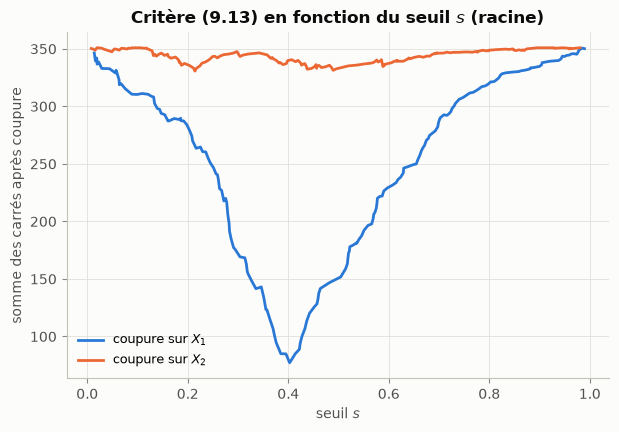

In [4]:
N = 200
Xr = rng.uniform(0, 1, (N, 2))
fr = np.where(Xr[:, 0] <= 0.4, np.where(Xr[:, 1] <= 0.6, -1.0, 0.5), 2.0)
yr = fr + 0.4 * rng.randn(N)

fig, ax = plt.subplots(figsize=(7, 4.5))
for j in range(2):
    o = np.argsort(Xr[:, j])
    xs, ys = Xr[o, j], yr[o]
    n = np.arange(1, N)
    S1, S2 = np.cumsum(ys)[:-1], np.cumsum(ys ** 2)[:-1]
    rss = (S2 - S1 ** 2 / n) + ((ys ** 2).sum() - S2 - (ys.sum() - S1) ** 2 / (N - n))
    ax.plot(0.5 * (xs[1:] + xs[:-1]), rss, color=COLORS[j], label="coupure sur $X_%d$" % (j + 1))
ax.set(title="Critère (9.13) en fonction du seuil $s$ (racine)",
       xlabel="seuil $s$", ylabel="somme des carrés après coupure")
ax.legend()
plt.show()

La meilleure coupure de la racine porte sur $X_1$ près de $0.4$, conformément à la
fonction simulée $f$ (constante par morceaux à trois régions). Faisons croître l'arbre
jusqu'à 3 feuilles et traçons la partition obtenue.

In [5]:
arbre_r = ArbreCART(task="regression", max_leaves=3).fit(Xr, yr)
print(arbre_r.describe(names=["X1", "X2"]))

X1 < 0.4027
  X2 < 0.6012
    -> moyenne=-1.078
  X2 > 0.6012
    -> moyenne=0.489
X1 > 0.4027
  -> moyenne=1.964


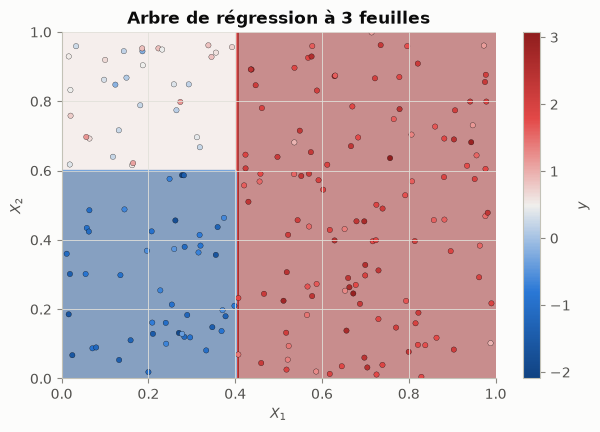

In [6]:
xx, yy = np.meshgrid(np.linspace(0, 1, 200), np.linspace(0, 1, 200))
zz = arbre_r.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(7, 4.5))
cs = ax.contourf(xx, yy, zz, levels=20, cmap=DIV, alpha=0.5)
sc = ax.scatter(Xr[:, 0], Xr[:, 1], c=yr, cmap=DIV, s=15, edgecolor="k", lw=0.2)
fig.colorbar(sc, ax=ax, label="$y$")
ax.set(title="Arbre de régression à 3 feuilles", xlabel="$X_1$", ylabel="$X_2$")
plt.show()

## 3. Taille de l'arbre et élagage coût-complexité

Un arbre trop grand sur-apprend, un arbre trop petit manque la structure : la **taille**
est le paramètre de complexité. S'arrêter dès qu'une coupure n'apporte pas assez est
une mauvaise idée (« myopie ») : une coupure en apparence inutile peut préparer une très
bonne coupure en dessous (penser à un « ou exclusif »). La stratégie de CART est donc :

1. faire croître un **grand arbre** $T_0$ (on ne s'arrête que lorsque les nœuds sont très
   petits, par exemple moins de 5 observations) ;
2. l'**élaguer**.

### Le critère coût-complexité

Un **sous-arbre** $T\subset T_0$ s'obtient en « refermant » des nœuds internes de $T_0$
(on remplace une branche par une feuille). On note $|T|$ le nombre de feuilles et, pour
la feuille $m$ de région $R_m$ (éq. (9.15)) :
$$N_m = \#\{x_i\in R_m\},\quad \hat c_m = \frac1{N_m}\sum_{x_i\in R_m}y_i,\quad
Q_m(T) = \frac1{N_m}\sum_{x_i\in R_m}(y_i-\hat c_m)^2 .$$
Le **critère coût-complexité** (éq. (9.16)) est
$$C_\alpha(T) = \sum_{m=1}^{|T|} N_m Q_m(T) + \alpha |T| .$$

Le premier terme est l'erreur d'ajustement (la somme des carrés résiduelle), le second
pénalise la taille : chaque feuille « coûte » $\alpha$. Pour $\alpha=0$ on garde $T_0$ ;
quand $\alpha$ augmente, on obtient des arbres de plus en plus petits. On montre que pour
chaque $\alpha$ il existe un **unique plus petit** sous-arbre $T_\alpha$ minimisant
$C_\alpha$.

### L'élagage du maillon le plus faible

Notons $R(t)$ l'erreur (somme des carrés) du nœud $t$ s'il devient une feuille, et
$R(T_t)$, $|T_t|$ l'erreur et le nombre de feuilles de la **branche** issue de $t$.
Refermer $t$ change $C_\alpha$ de
$$\big[R(t)+\alpha\big] - \big[R(T_t)+\alpha|T_t|\big] = R(t)-R(T_t) - \alpha(|T_t|-1).$$
Refermer $t$ devient avantageux dès que
$$\alpha \ \ge\ g(t) = \frac{R(t)-R(T_t)}{|T_t|-1},$$
l'**augmentation d'erreur par feuille supprimée**. On referme successivement le nœud
interne de plus petit $g(t)$ (le « maillon le plus faible »), on met à jour les $g$, et
l'on recommence jusqu'à la racine.

On obtient une suite **finie et emboîtée** de sous-arbres $T_0\supset T_1\supset\dots
\supset\{\text{racine}\}$ et des seuils $0=\alpha_0<\alpha_1<\dots$ ; on peut montrer
(Breiman et al., 1984) que $T_\alpha = T_k$ pour $\alpha\in[\alpha_k,\alpha_{k+1})$.
Enfin $\alpha$ est choisi par **validation croisée** (5 ou 10 plis).

In [7]:
arbre_g = ArbreCART(task="regression", min_samples_split=5).fit(Xr, yr)
alphas, sous_arbres = arbre_g.pruning_path()
tailles = [arbre_g.n_leaves(m) for m in sous_arbres]
print("taille de T0 :", arbre_g.n_leaves())
print("nombre de sous-arbres de la suite :", len(alphas))
print("tailles :", tailles[:12], "...", tailles[-6:])

taille de T0 : 76
nombre de sous-arbres de la suite : 55
tailles : [76, 75, 74, 73, 72, 71, 70, 69, 68, 67, 66, 65] ... [6, 5, 4, 3, 2, 1]


Vérifions numériquement que, pour plusieurs valeurs de $\alpha$, le sous-arbre de la
suite minimise bien $C_\alpha$ parmi tous les sous-arbres de la suite, et visualisons
$C_\alpha(T_k)$.

alpha = 0.3 : minimum en |T| = 39 ; T_alpha a 39 feuilles
alpha = 2.0 : minimum en |T| = 3 ; T_alpha a 3 feuilles
alpha = 30.0 : minimum en |T| = 3 ; T_alpha a 3 feuilles


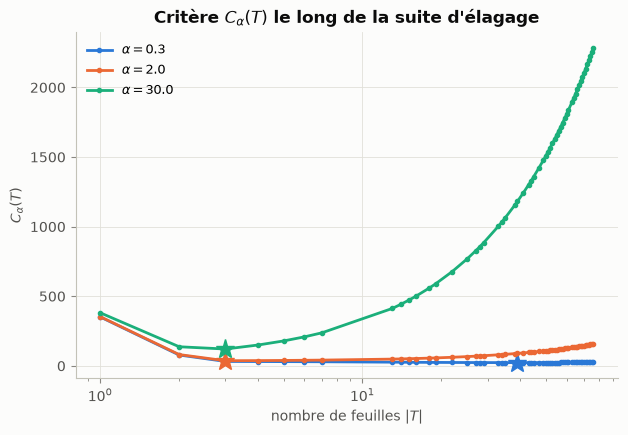

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for c_i, a in enumerate([0.3, 2.0, 30.0]):
    Ca = [arbre_g._subtree_stats(m)[0][0] + a * arbre_g.n_leaves(m) for m in sous_arbres]
    k = int(np.argmin(Ca))
    ax.plot(tailles, Ca, "o-", ms=3, color=COLORS[c_i], label=r"$\alpha=%.1f$" % a)
    ax.plot(tailles[k], Ca[k], "*", ms=14, color=COLORS[c_i])
    choisi = arbre_g.n_leaves(arbre_g.subtree(a))
    print("alpha = %.1f : minimum en |T| = %d ; T_alpha a %d feuilles" % (a, tailles[k], choisi))
ax.set(title=r"Critère $C_\alpha(T)$ le long de la suite d'élagage",
       xlabel="nombre de feuilles $|T|$", ylabel=r"$C_\alpha(T)$", xscale="log")
ax.legend()
plt.show()

Choisissons maintenant $\alpha$ par validation croisée à 10 plis. Pour chaque pli on
fait croître un arbre sur les 9 autres, on calcule sa propre suite d'élagage et on
évalue $T_\alpha$ sur le pli mis de côté. Les valeurs de $\alpha$ testées sont les
moyennes géométriques $\sqrt{\alpha_k\alpha_{k+1}}$ (un représentant de chaque
intervalle).

In [9]:
beta = np.r_[np.sqrt(alphas[:-1] * alphas[1:]), alphas[-1] * 1.5]
E = cart_cv(Xr, yr, beta, n_folds=10, rng=np.random.RandomState(1), task="regression")
cv, se = E.mean(0), E.std(0, ddof=1) / np.sqrt(10)
k_min = int(np.argmin(cv))
print("taille choisie par validation croisée :", tailles[k_min])
print(arbre_g.describe(names=["X1", "X2"], is_leaf=sous_arbres[k_min]))

taille choisie par validation croisée : 3
X1 < 0.4027
  X2 < 0.6012
    -> moyenne=-1.078
  X2 > 0.6012
    -> moyenne=0.489
X1 > 0.4027
  -> moyenne=1.964


La validation croisée retrouve un arbre proche de la vraie structure à 3 régions (en
présence de bruit, quelques coupures supplémentaires peuvent subsister).

## 4. Arbres de classification

Si la réponse prend les valeurs $1,\dots,K$, seul le **critère de coupure** change. Dans
le nœud $m$ (région $R_m$, $N_m$ observations), on note
$$\hat p_{mk} = \frac{1}{N_m}\sum_{x_i\in R_m}\mathbb 1(y_i=k)$$
la proportion de la classe $k$ ; le nœud est affecté à la classe majoritaire
$k(m)=\arg\max_k \hat p_{mk}$.

Mesures d'**impureté** $Q_m(T)$ du nœud (éq. (9.17)) :

- erreur de classement : $\frac1{N_m}\sum_{i\in R_m}\mathbb 1(y_i\ne k(m)) = 1-\hat
  p_{mk(m)}$ ;
- indice de Gini : $\sum_{k\ne k'}\hat p_{mk}\hat p_{mk'} = \sum_{k=1}^K \hat
  p_{mk}(1-\hat p_{mk})$ ;
- entropie croisée (déviance) : $-\sum_{k=1}^K \hat p_{mk}\log\hat p_{mk}$.

Pour deux classes, avec $p$ la proportion de la classe 2, elles valent
$1-\max(p,1-p)$, $2p(1-p)$ et $-p\log p-(1-p)\log(1-p)$.

> **Rappel (entropie).** La quantité $-\sum_k p_k\log p_k$ est l'**entropie** de la loi
> $(p_1,\dots,p_K)$ : elle est nulle pour une loi concentrée sur une classe (nœud
> « pur ») et maximale pour la loi uniforme. Elle mesure le « désordre » du nœud. Elle
> est aussi égale à $-\frac{1}{N_m}$ fois la log-vraisemblance multinomiale maximisée
> du nœud : d'où le nom de **déviance**.

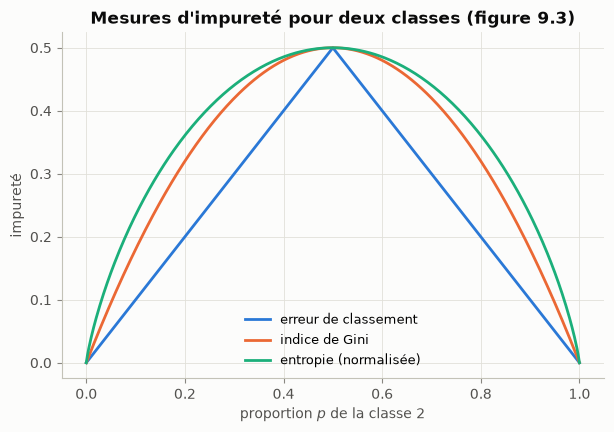

In [10]:
p = np.linspace(0, 1, 401)
P = np.c_[1 - p, p]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(p, impurity(P, "misclass"), color=COLORS[0], label="erreur de classement")
ax.plot(p, impurity(P, "gini"), color=COLORS[1], label="indice de Gini")
ent = impurity(P, "entropy")
ax.plot(p, ent / ent.max() * 0.5, color=COLORS[2], label="entropie (normalisée)")
ax.set(title="Mesures d'impureté pour deux classes (figure 9.3)",
       xlabel="proportion $p$ de la classe 2", ylabel="impureté")
ax.legend()
plt.show()

L'entropie est renormalisée pour passer par $(0.5, 0.5)$, comme dans le livre. Les trois
courbes se ressemblent, mais Gini et entropie sont **dérivables** et **strictement
concaves**, alors que l'erreur de classement est affine par morceaux.

### Pourquoi faire croître l'arbre avec Gini ou l'entropie ?

Pour comparer des coupures, on pondère l'impureté de chaque fils par son effectif :
$N_{L}Q_{L} + N_{R}Q_{R}$ (c'est l'analogue de (9.13)). Exemple du livre : un nœud à
(400, 400) observations des deux classes, et deux coupures possibles :

- coupure A : fils (300, 100) et (100, 300) ;
- coupure B : fils (200, 400) et (200, 0).

In [11]:
def cout(fils, crit):
    return sum(sum(c) * impurity(np.array(c) / sum(c), crit) for c in fils)

A = [(300, 100), (100, 300)]
B = [(200, 400), (200, 0)]
tab = pd.DataFrame({crit: [cout(A, crit), cout(B, crit)]
                    for crit in ["misclass", "gini", "entropy"]}, index=["coupure A", "coupure B"])
tab.round(1)

,misclass,gini,entropy
coupure A,200.0,300.0,449.9
coupure B,200.0,266.7,381.9


Les deux coupures ont la même erreur de classement (200 observations mal classées,
soit 25 %), mais la coupure B crée un nœud **pur**, sans doute préférable pour la suite.
Gini et entropie la préfèrent (valeur plus faible) : ils sont **plus sensibles** aux
changements des proportions.

**Explication par la concavité.** Si un nœud de proportion $p$ est coupé en deux fils
de proportions $p_L, p_R$ et de poids $\pi_L,\pi_R$ ($\pi_L+\pi_R=1$), alors
$p = \pi_Lp_L+\pi_Rp_R$. Pour une fonction $Q$ **strictement concave**, l'inégalité de
Jensen donne $\pi_LQ(p_L)+\pi_RQ(p_R) < Q(p)$ dès que $p_L\ne p_R$ : **toute** coupure
qui modifie les proportions fait baisser l'impureté. Pour l'erreur de classement,
affine de part et d'autre de $1/2$, l'inégalité est une égalité si $p_L$ et $p_R$ sont
du même côté de $1/2$ : la coupure semble alors inutile, même si elle prépare la suite.

On fait donc croître l'arbre avec Gini ou l'entropie ; pour l'**élagage**, on peut
utiliser n'importe quelle mesure, typiquement l'erreur de classement (c'est ce que fait
notre `pruning_path` en classification : $R(t)$ = nombre pondéré d'erreurs).

### Deux interprétations de l'indice de Gini

1. **Règle randomisée.** Au lieu de prédire la classe majoritaire, on prédit la classe
   $k$ avec probabilité $\hat p_{mk}$. Une observation de classe $k$ (fréquence $\hat
   p_{mk}$) est mal classée avec probabilité $1-\hat p_{mk}$ : l'erreur d'apprentissage
   est $\sum_k\hat p_{mk}(1-\hat p_{mk})$, l'indice de Gini.
2. **Variance.** Codons $1$ si l'observation est de classe $k$ et $0$ sinon : la variance
   empirique de ce codage dans le nœud vaut $\hat p_{mk}(1-\hat p_{mk})$. En sommant sur
   $k$ on retrouve Gini.

In [12]:
y_noeud = rng.choice(3, size=500, p=[0.5, 0.3, 0.2])
pk = np.bincount(y_noeud, minlength=3) / 500
gini = np.sum(pk * (1 - pk))
var = sum(np.var(y_noeud == k) for k in range(3))
pred_alea = np.array([rng.choice(3, p=pk) for _ in range(20000)])
vraies = rng.choice(y_noeud, 20000)
print("Gini : %.4f   somme des variances : %.4f   erreur de la règle randomisée : %.4f"
      % (gini, var, np.mean(pred_alea != vraies)))

Gini : 0.6072   somme des variances : 0.6072   erreur de la règle randomisée : 0.6006


> **À retenir.** Un arbre de classification se fait croître avec un critère concave
> (Gini ou entropie, éventuellement pondérés par les effectifs des fils), puis s'élague
> avec, le plus souvent, l'erreur de classement.

## 5. Autres questions pratiques

### Prédicteurs qualitatifs

Un prédicteur qualitatif à $q$ modalités non ordonnées admet $2^{q-1}-1$ partitions en
deux groupes : trop pour $q$ grand. Pour une réponse **binaire**, il suffit de trier les
modalités selon la proportion de la classe 1 dans chacune, puis de couper comme pour une
variable ordonnée : on obtient la coupure optimale (pour Gini ou l'entropie) parmi les
$2^{q-1}-1$ possibles. Vérifions-le sur un exemple.

In [13]:
from itertools import combinations
q = 7
mod = rng.randint(0, q, 600)
prob = rng.uniform(0.1, 0.9, q)
yq = (rng.uniform(size=600) < prob[mod]).astype(int)

def gini_partition(gauche):
    g = np.isin(mod, gauche)
    tot = 0.0
    for part in (g, ~g):
        if part.sum():
            pk_ = yq[part].mean()
            tot += part.sum() * 2 * pk_ * (1 - pk_)
    return tot

toutes = [list(c) for r in range(1, q) for c in combinations(range(q), r) if 0 in c]
meilleure = min(toutes, key=gini_partition)
ordre = np.argsort([yq[mod == k].mean() for k in range(q)])
ordonnees = [list(ordre[:r]) for r in range(1, q)]
meilleure_ord = min(ordonnees, key=gini_partition)
print("nombre de partitions examinées : %d (force brute) contre %d (après tri)"
      % (len(toutes), len(ordonnees)))
print("Gini optimal force brute : %.3f   après tri : %.3f"
      % (gini_partition(meilleure), gini_partition(meilleure_ord)))

nombre de partitions examinées : 63 (force brute) contre 6 (après tri)
Gini optimal force brute : 252.618   après tri : 252.618


> **Remarque.** Le résultat vaut aussi pour une réponse quantitative et la perte
> quadratique (on trie selon la moyenne de $y$), mais pas pour plus de deux classes.
> Attention : les prédicteurs à très nombreuses modalités offrent tant de partitions
> qu'ils sont favorisés à tort, ce qui peut entraîner un fort sur-apprentissage.

### Matrice de pertes

Si classer une observation de classe $k$ en $k'$ coûte $L_{kk'}$ (avec $L_{kk}=0$), on
peut, pour deux classes, **pondérer** les observations de la classe $k$ par $L_{kk'}$ :
cela modifie les probabilités *a priori* des classes. Dans une feuille, la règle de
Bayes empirique affecte à la classe $k(m)=\arg\min_k\sum_\ell L_{\ell k}\hat p_{m\ell}$.
(Modifier l'indice de Gini en $\sum_{k\ne k'}L_{kk'}\hat p_{mk}\hat p_{mk'}$ n'a aucun
effet pour deux classes, car le coefficient de $\hat p_{m1}\hat p_{m2}$ devient
$L_{12}+L_{21}$, une constante.)

### Valeurs manquantes, coupures binaires, coupures obliques

- **Valeurs manquantes** : pour un prédicteur qualitatif, on crée une modalité
  « manquant » ; plus généralement CART utilise des **coupures de substitution**
  (*surrogate splits*), qui imitent au mieux la coupure principale à l'aide d'autres
  variables (voir le notebook 3).
- **Pourquoi des coupures binaires ?** Des coupures multiples fragmentent les données
  trop vite ; une coupure multiple s'obtient d'ailleurs par plusieurs coupures binaires.
- **Combinaisons linéaires** $\sum_j a_jX_j\le s$ : plus puissantes mais moins lisibles
  et difficiles à optimiser ; les mélanges hiérarchiques d'experts (section 9.5) en sont
  une version « douce ».
- C4.5/C5.0 (Quinlan) est l'autre grande famille d'arbres ; sa particularité est de
  simplifier l'arbre en un **ensemble de règles**.